In [19]:
from langgraph.graph import StateGraph , START , END
from typing import TypedDict


In [20]:
class BatsmanState(TypedDict):
    runs : int
    balls : int
    fours : int
    sixes : int

    sr : float
    bpb : float
    boundary_percent : float

In [21]:
def calculate_sr(state : BatsmanState) -> BatsmanState:

    sr = (state['runs']/state['balls'])/100

    state['sr'] = sr 
       
    return state 

def calculate_bpb(state : BatsmanState) -> BatsmanState:
    
    bpb = state['balls']/(state['fours'] + state['sixes'])

    state['bpb'] = bpb
    return state

def calculate_boundary_percent(state : BatsmanState) -> BatsmanState:

    bp = ((state['fours'] * 4)  + (state['sixes'] * 6))/(state['runs']) * 100

    state['boundary_percent'] = bp

    return state

def summary(state : BatsmanState) -> BatsmanState:
    summary = f""" 
Strike rate - {state['sr']}
balls per boundary - {state['bpb']}
boundary percent - {state['boundary_percent']}
"""
    
    state['summary'] = summary

    return state

In [22]:
graph = StateGraph(BatsmanState)

graph.add_node('calculate_sr' , calculate_sr)

graph.add_node('calculate_bpb' , calculate_bpb)

graph.add_node('calculate_boundary_percent' , calculate_boundary_percent)

graph.add_node('summary' , summary)


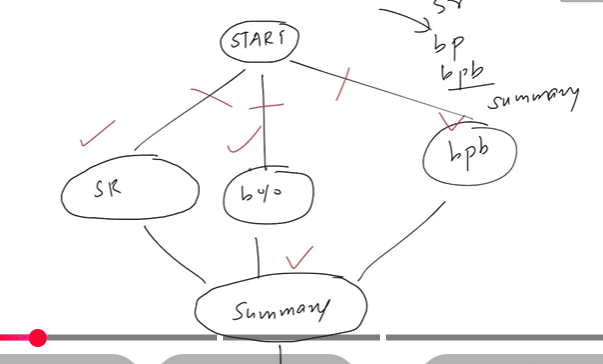

In [23]:
graph.add_edge(START , 'calculate_sr')
graph.add_edge(START , 'calculate_bpb')
graph.add_edge(START , 'calculate_boundary_percent')


graph.add_edge('calculate_sr' , 'summary')
graph.add_edge( 'calculate_bpb' , 'summary')
graph.add_edge( 'calculate_boundary_percent' , 'summary')

graph.add_edge('summary' , END)

In [24]:
workflow = graph.compile()

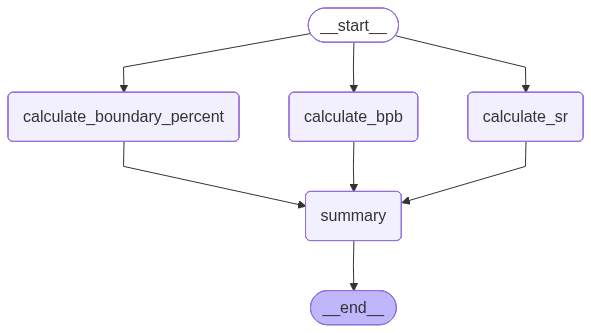

In [25]:
workflow

In [26]:
initial_state = {
    'runs' : 100,
    'balls' : 50,
    'fours' : 5,
    'sixes' : 8
}

In [27]:
final_state = workflow.invoke(initial_state) 

InvalidUpdateError: At key 'runs': Can receive only one value per step. Use an Annotated key to handle multiple values.
For troubleshooting, visit: https://python.langchain.com/docs/troubleshooting/errors/INVALID_CONCURRENT_GRAPH_UPDATE

In [28]:
# InvalidUpdateError: At key 'runs': Can receive only one value per step. Use an Annotated key to handle multiple values.
# For troubleshooting, visit: https://python.langchain.com/docs/troubleshooting/errors/INVALID_CONCURRENT_GRAPH_UPDATE

# WHY THIS ERROR?


# THIS IS BECAUSE WE ARE SENDING STATES FROM ALL 3 NODES TO SUMMARY PARALLELY , SO THE SUMMARY NODE DOES NOT KNOW WHICH NODE'S STATE TO USE??? SO INSTEAD OF RETURNING THE WHOLE STATE , ONLY RETURN WHAT IS BEING CALCULATED IN THAT PARTICULAR NODE

In [29]:
def calculate_sr(state : BatsmanState) -> BatsmanState:

    sr = (state['runs']/state['balls'])/100

    state['sr'] = sr 
       
    return {'sr' : sr}

def calculate_bpb(state : BatsmanState) -> BatsmanState:
    
    bpb = state['balls']/(state['fours'] + state['sixes'])

    # state['bpb'] = bpb
    return {'bpb' : bpb}

def calculate_boundary_percent(state : BatsmanState) -> BatsmanState:

    bp = ((state['fours'] * 4)  + (state['sixes'] * 6))/(state['runs']) * 100

    state['boundary_percent'] = bp

    return {'boundary_percent' : bp}

def summary(state : BatsmanState) -> BatsmanState:
    summary = f""" 
Strike rate - {state['sr']}
balls per boundary - {state['bpb']}
boundary percent - {state['boundary_percent']}
"""
    
    state['summary'] = summary

    return state

In [30]:
graph = StateGraph(BatsmanState)

graph.add_node('calculate_sr' , calculate_sr)

graph.add_node('calculate_bpb' , calculate_bpb)

graph.add_node('calculate_boundary_percent' , calculate_boundary_percent)

graph.add_node('summary' , summary)


In [31]:
graph.add_edge(START , 'calculate_sr')
graph.add_edge(START , 'calculate_bpb')
graph.add_edge(START , 'calculate_boundary_percent')


graph.add_edge('calculate_sr' , 'summary')
graph.add_edge( 'calculate_bpb' , 'summary')
graph.add_edge( 'calculate_boundary_percent' , 'summary')

graph.add_edge('summary' , END)

In [32]:
workflow = graph.compile()

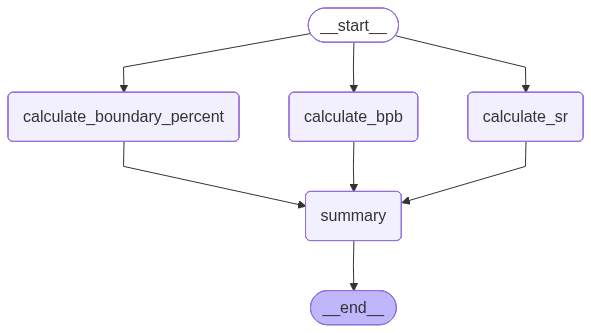

In [33]:
workflow

In [34]:
final_state = workflow.invoke(initial_state) 

In [35]:
final_state

{'runs': 100,
 'balls': 50,
 'fours': 5,
 'sixes': 8,
 'sr': 0.02,
 'bpb': 3.8461538461538463,
 'boundary_percent': 68.0}